# Semana 8 · Implementación y comparación de algoritmos de clasificación
**CADI · Introducción a Machine Learning** · Universidad de Cundinamarca
**Autor:** Jampier Santiago Moreno Arenas

En este notebook aplico cinco algoritmos de clasificación (Decision Tree, Random Forest, SVM, K-NN y Naive Bayes) sobre el mismo problema, con la misma partición de datos y las mismas métricas, para poder compararlos de forma justa y decidir cuál usaría.

> **Alcance:** el dataset se usa solo con fines académicos. Los resultados no sirven como herramienta clínica.

## 1. Preparación del caso y los datos

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

# Cargar el dataset en formato DataFrame
data = load_breast_cancer(as_frame=True)
X = data.data.copy()

# En sklearn target=0 es maligno. Lo invierto para que la clase positiva (1) sea 'maligno'
y = (data.target == 0).astype(int)

print("Forma de X (observaciones, variables):", X.shape)
print("\nConteo de la variable objetivo (1 = maligno, 0 = benigno):")
print(y.value_counts())
print("\nProporciones:")
print(y.value_counts(normalize=True).round(4))

Forma de X (observaciones, variables): (569, 30)

Conteo de la variable objetivo (1 = maligno, 0 = benigno):
target
0    357
1    212
Name: count, dtype: int64

Proporciones:
target
0    0.6274
1    0.3726
Name: proportion, dtype: float64


**¿Cuántas observaciones y variables contiene el conjunto de datos?**
569 observaciones y 30 variables de entrada, todas numéricas continuas (media, error estándar y valor "worst" de 10 medidas del núcleo celular, como radio, textura, perímetro, área y concavidad).

**¿La variable objetivo está balanceada?**
No del todo, pero tampoco está en un desbalance severo: hay 357 casos benignos (62,7 %) y 212 malignos (37,3 %). Un modelo que siempre respondiera "benigno" ya tendría 62,7 % de accuracy sin aprender nada, así que ese número solo no basta para juzgar los modelos.

**¿Por qué es importante definir con claridad qué representa la clase positiva?**
Porque Precision, Recall y F1 se calculan respecto a la clase positiva. Aquí positivo = maligno, entonces un falso negativo es un caso maligno que el modelo dejó pasar. Si no hubiera invertido la etiqueta (en sklearn 0 es maligno), las métricas estarían midiendo la clase benigna y el Recall significaría otra cosa. También define cómo se leen los falsos positivos y falsos negativos en la matriz de confusión.

### División entrenamiento / prueba

In [4]:
# Misma partición para los cinco modelos: 80/20, random_state=42 y estratificada
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("% maligno en train:", round(y_train.mean() * 100, 2))
print("% maligno en test :", round(y_test.mean() * 100, 2))
print("Malignos en test  :", y_test.sum(), "de", len(y_test))

Train: (455, 30) | Test: (114, 30)
% maligno en train: 37.36
% maligno en test : 36.84
Malignos en test  : 42 de 114


**¿Qué función cumple `stratify=y`?**
Mantiene la proporción de las clases en ambos subconjuntos. Con ella, el train tiene 37,4 % de malignos y el test 36,8 % (42 de 114), prácticamente la proporción original. Sin estratificar, el azar podría dejar el test con muy pocos malignos y las métricas del Recall serían poco confiables.

### Función común de evaluación

In [5]:
def evaluar_modelo(nombre, modelo, X_eval, y_eval):
    """Calcula las cinco métricas y devuelve un diccionario para armar la tabla final.
    La matriz de confusión se imprime con el formato [[TN, FP], [FN, TP]]."""
    pred = modelo.predict(X_eval)
    tn, fp, fn, tp = confusion_matrix(y_eval, pred).ravel()
    resultados = {
        'Modelo': nombre,
        'Accuracy': accuracy_score(y_eval, pred),
        'Precision': precision_score(y_eval, pred),
        'Recall': recall_score(y_eval, pred),
        'F1': f1_score(y_eval, pred),
        'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp
    }
    print(nombre)
    print(confusion_matrix(y_eval, pred))
    print(f"Accuracy={resultados['Accuracy']:.4f} | Precision={resultados['Precision']:.4f} | "
          f"Recall={resultados['Recall']:.4f} | F1={resultados['F1']:.4f}\n")
    return resultados

resultados = []   # aquí voy acumulando los resultados de cada modelo
modelos = {}      # y aquí guardo los modelos entrenados

## 2. Decision Tree (Árbol de Decisión)

In [6]:
modelo_dt = DecisionTreeClassifier(max_depth=4, random_state=42)
modelo_dt.fit(X_train, y_train)                       # entrenamiento
modelos['Decision Tree'] = modelo_dt
resultados.append(evaluar_modelo('Decision Tree', modelo_dt, X_test, y_test))

Decision Tree
[[70  2]
 [ 8 34]]
Accuracy=0.9123 | Precision=0.9444 | Recall=0.8095 | F1=0.8718



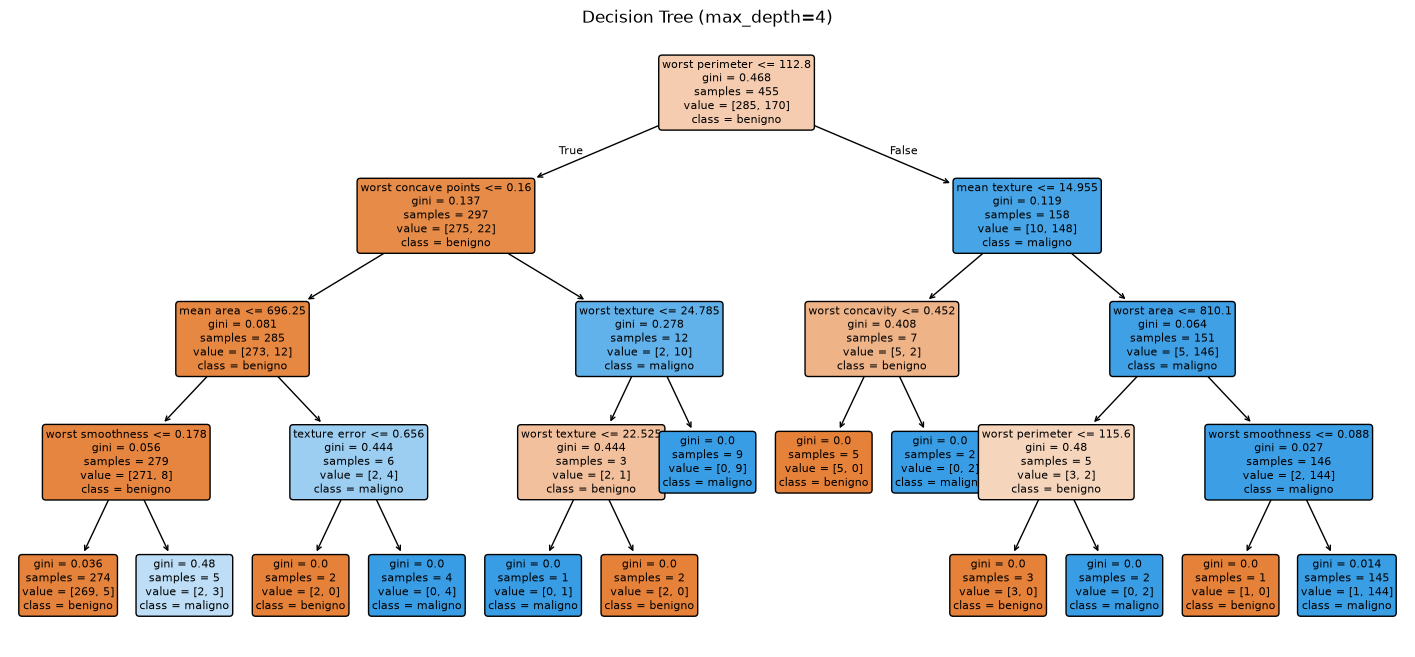

In [7]:
# Visualización del árbol: sirve para ver qué reglas aprendió
plt.figure(figsize=(18, 8))
plot_tree(modelo_dt, feature_names=X.columns, class_names=['benigno', 'maligno'],
          filled=True, rounded=True, fontsize=8)
plt.title("Decision Tree (max_depth=4)")
plt.show()

**¿Qué ventaja tiene limitar la profundidad del árbol?**
Evita que el árbol memorice el train (sobreajuste) y lo mantiene legible: con profundidad 4 son pocas reglas y se puede leer de arriba abajo. El costo es que puede quedarse corto y no capturar patrones más finos.

**¿Qué errores observas en la matriz de confusión?**
Cometió 2 falsos positivos y 8 falsos negativos. Los 8 falsos negativos son lo que más pesa: de 42 casos malignos dejó pasar 8, por eso su Recall es el más bajo de todos (0,8095) aunque la Precision se vea bien (0,9444).

## 3. Random Forest

In [8]:
modelo_rf = RandomForestClassifier(n_estimators=100, random_state=42)
modelo_rf.fit(X_train, y_train)
modelos['Random Forest'] = modelo_rf
resultados.append(evaluar_modelo('Random Forest', modelo_rf, X_test, y_test))

Random Forest
[[72  0]
 [ 3 39]]
Accuracy=0.9737 | Precision=1.0000 | Recall=0.9286 | F1=0.9630



In [9]:
# Variables que más usa el bosque (importancia por reducción de impureza)
imp = pd.Series(modelo_rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print(imp.head(5).round(3))

worst area              0.151
worst concave points    0.126
worst radius            0.093
worst perimeter         0.084
mean concave points     0.081
dtype: float64


**¿Qué cambia al pasar de un árbol individual a un conjunto de árboles?**
Cada uno de los 100 árboles se entrena con una muestra distinta de los datos y con subconjuntos aleatorios de variables, y la predicción final sale de la votación. Eso reduce la varianza: los errores individuales tienden a compensarse. A cambio se pierde la lectura directa de reglas; lo que queda son las importancias de variables (arriba, *worst area* y *worst concave points* encabezan la lista). Ojo con que aquí el bosque crece sin límite de profundidad, mientras que el árbol anterior tenía `max_depth=4`, así que parte de la mejora también viene de ahí.

**¿Mejora alguna métrica? ¿Cuál y cuánto?**
Mejora todas frente al Decision Tree: Accuracy de 0,9123 a 0,9737 (+6,1 puntos), Precision de 0,9444 a 1,0, Recall de 0,8095 a 0,9286 (+11,9 puntos) y F1 de 0,8718 a 0,9630. Los falsos negativos bajaron de 8 a 3 y los falsos positivos de 2 a 0.

## 4. Support Vector Machine (SVM)

In [10]:
# Para ver por qué importa la escala: rango de dos variables
print(X[['mean smoothness', 'mean area']].describe().loc[['min', 'max']])

     mean smoothness  mean area
min          0.05263      143.5
max          0.16340     2501.0


In [11]:
# El StandardScaler va dentro del Pipeline: se ajusta solo con train y luego se aplica a test
modelo_svm = make_pipeline(
    StandardScaler(),
    SVC(kernel='rbf', C=1.0, gamma='scale')
)
modelo_svm.fit(X_train, y_train)
modelos['SVM'] = modelo_svm
resultados.append(evaluar_modelo('SVM', modelo_svm, X_test, y_test))

SVM
[[72  0]
 [ 3 39]]
Accuracy=0.9737 | Precision=1.0000 | Recall=0.9286 | F1=0.9630



**¿Por qué en este modelo usamos `StandardScaler`?**
El kernel RBF trabaja con distancias entre observaciones. Las variables tienen escalas muy distintas (*mean smoothness* va de 0,05 a 0,16 y *mean area* de 143 a 2501), así que sin escalar las de mayor magnitud dominarían y las demás casi no influirían. Meterlo en el Pipeline además evita fuga de datos: el escalador solo "ve" el train.

**¿Qué resultado obtiene SVM frente a los modelos basados en árboles?**
Iguala a Random Forest en el test (Accuracy 0,9737, Precision 1,0, Recall 0,9286, F1 0,9630, misma matriz de confusión con 0 falsos positivos y 3 falsos negativos) y supera claramente al Decision Tree.

## 5. K-Nearest Neighbors (K-NN)

In [12]:
modelo_knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)
modelo_knn.fit(X_train, y_train)
modelos['K-NN'] = modelo_knn
resultados.append(evaluar_modelo('K-NN', modelo_knn, X_test, y_test))

K-NN
[[71  1]
 [ 4 38]]
Accuracy=0.9561 | Precision=0.9744 | Recall=0.9048 | F1=0.9383



**¿Qué representa k=5 en este algoritmo?**
Que para clasificar una muestra nueva el modelo busca los 5 puntos del train más cercanos y se queda con la clase mayoritaria entre ellos. Un k pequeño es más sensible al ruido; uno grande suaviza demasiado la frontera. Aquí no lo ajusté, usé el valor que pide la guía.

**¿Por qué el escalamiento es especialmente importante cuando se calculan distancias?**
Porque la distancia euclidiana suma diferencias al cuadrado de todas las variables: una variable medida en miles (como el área) pesaría muchísimo más que una medida en décimas (como la suavidad) y "decidiría" quiénes son los vecinos. K-NN no aprende parámetros, solo compara distancias, por eso es todavía más dependiente de la escala. Quedó en Accuracy 0,9561 con 1 falso positivo y 4 falsos negativos, un poco por debajo de SVM y Random Forest.

## 6. Naive Bayes (GaussianNB)

In [13]:
modelo_nb = GaussianNB()     # sin escalamiento, como indica la guía
modelo_nb.fit(X_train, y_train)
modelos['Naive Bayes'] = modelo_nb
resultados.append(evaluar_modelo('Naive Bayes', modelo_nb, X_test, y_test))

Naive Bayes
[[72  0]
 [ 7 35]]
Accuracy=0.9386 | Precision=1.0000 | Recall=0.8333 | F1=0.9091



In [14]:
# Revisión del supuesto de independencia: correlación entre variables de tamaño
print("radio vs perímetro:", round(X['mean radius'].corr(X['mean perimeter']), 3))
print("radio vs área     :", round(X['mean radius'].corr(X['mean area']), 3))

radio vs perímetro: 0.998
radio vs área     : 0.987


**¿Qué supuesto simplificador utiliza Naive Bayes respecto a las variables?**
Asume que las variables son independientes entre sí dado la clase (y, en la versión Gaussiana, que cada una sigue una distribución normal dentro de cada clase). En este dataset eso se cumple mal: radio, perímetro y área tienen correlaciones de 0,99 o más porque miden básicamente lo mismo.

**¿En qué métricas se comporta mejor o peor que los otros clasificadores?**
Tiene Precision de 1,0 (cero falsos positivos, igual que Random Forest y SVM), pero su Recall es 0,8333 con 7 falsos negativos, el segundo peor después del Decision Tree. Es decir, casi no da falsas alarmas pero deja pasar bastantes casos malignos. Su Accuracy (0,9386) queda por debajo de K-NN, SVM y Random Forest.

## 7. Comparación y toma de decisión

In [15]:
tabla = pd.DataFrame(resultados).set_index('Modelo')
tabla_metricas = tabla[['Accuracy', 'Precision', 'Recall', 'F1', 'FP', 'FN']].round(4)
tabla_metricas

,Accuracy,Precision,Recall,F1,FP,FN
Modelo,,,,,,
Decision Tree,0.9123,0.9444,0.8095,0.8718,2,8
Random Forest,0.9737,1.0000,0.9286,0.9630,0,3
SVM,0.9737,1.0000,0.9286,0.9630,0,3
K-NN,0.9561,0.9744,0.9048,0.9383,1,4
Naive Bayes,0.9386,1.0000,0.8333,0.9091,0,7


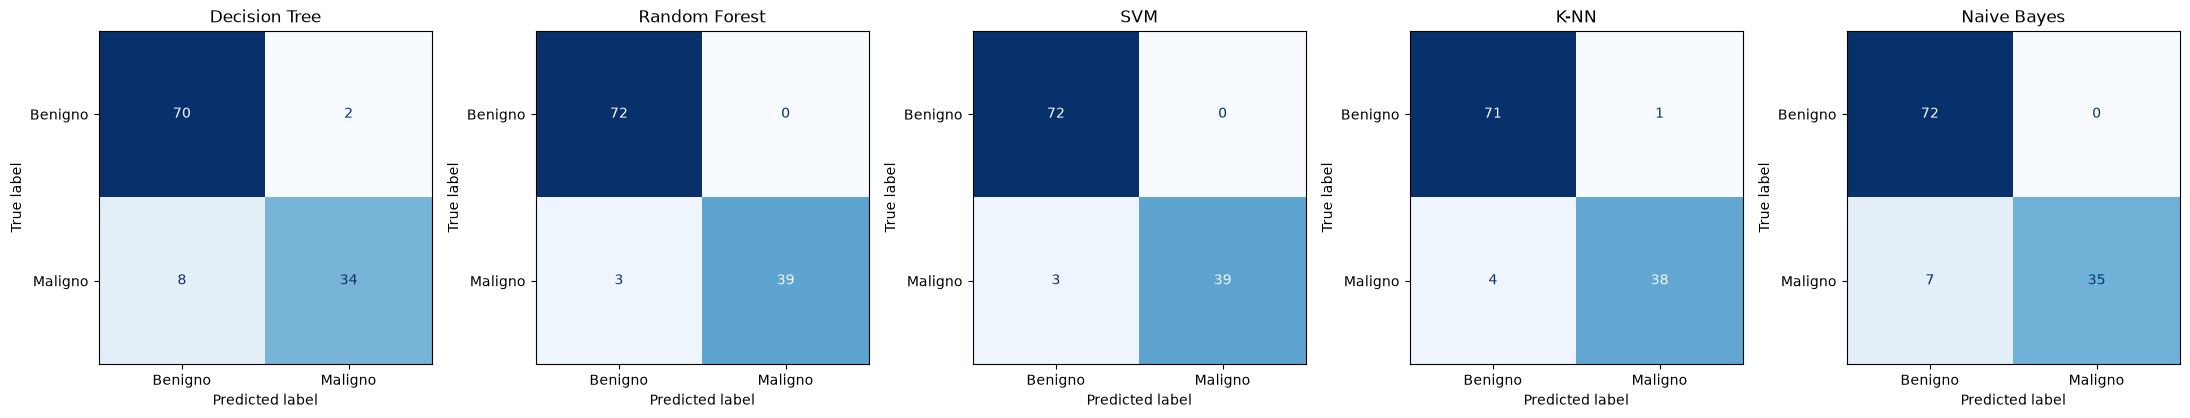

In [16]:
# Matrices de confusión de los cinco modelos lado a lado
fig, axes = plt.subplots(1, 5, figsize=(22, 4.2))
for ax, (nombre, m) in zip(axes, modelos.items()):
    ConfusionMatrixDisplay.from_estimator(
        m, X_test, y_test, display_labels=['Benigno', 'Maligno'],
        cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(nombre)
plt.tight_layout()
plt.savefig('matrices_confusion.png', dpi=150, bbox_inches='tight')
plt.show()

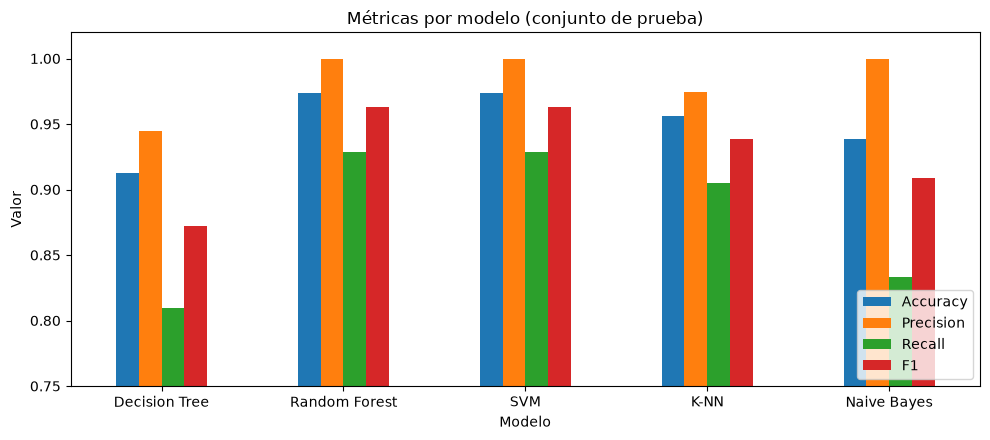

In [17]:
# Comparación de métricas
tabla[['Accuracy', 'Precision', 'Recall', 'F1']].plot(kind='bar', figsize=(10, 4.5), ylim=(0.75, 1.02))
plt.title("Métricas por modelo (conjunto de prueba)")
plt.ylabel("Valor")
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('comparacion_metricas.png', dpi=150)
plt.show()

### Tabla comparativa con observaciones

| Modelo | Accuracy | Precision | Recall | F1 | FP | FN | Observación |
|---|---|---|---|---|---|---|---|
| Decision Tree | 0,9123 | 0,9444 | 0,8095 | 0,8718 | 2 | 8 | El más fácil de explicar, pero deja pasar 8 de 42 malignos. |
| Random Forest | 0,9737 | 1,0000 | 0,9286 | 0,9630 | 0 | 3 | Empata con SVM en todo; no necesita escalar. |
| SVM | 0,9737 | 1,0000 | 0,9286 | 0,9630 | 0 | 3 | Empata con RF; depende del escalamiento. |
| K-NN | 0,9561 | 0,9744 | 0,9048 | 0,9383 | 1 | 4 | Buen resultado con un modelo simple, un poco por debajo de SVM/RF. |
| Naive Bayes | 0,9386 | 1,0000 | 0,8333 | 0,9091 | 0 | 7 | Sin falsas alarmas, pero 7 malignos sin detectar. |

### Preguntas de análisis

**7. ¿Qué modelo obtuvo la mayor Accuracy?**
Random Forest y SVM, empatados con 0,9737 (111 de 114 predicciones correctas).

**8. ¿Qué modelo obtuvo el mayor Recall para la clase maligna?**
Otra vez Random Forest y SVM, con 0,9286 (detectaron 39 de los 42 malignos).

**9. ¿Qué modelo produjo menos falsos negativos?**
Random Forest y SVM con 3 cada uno. Después K-NN con 4, Naive Bayes con 7 y el Decision Tree con 8.

**10. ¿Coincide el modelo con mayor Accuracy con el que seleccionarías?**
Solo en parte, porque la Accuracy no desempata: hay dos modelos con el mismo valor y la misma matriz de confusión. Además es una métrica que puede tapar cosas: Naive Bayes tiene Precision perfecta y aun así deja pasar 7 malignos. Por eso miro el Recall y los falsos negativos, y al final me quedaría con SVM (ver sección 8 para el desempate).

**11. Si el costo de no detectar un caso maligno fuera especialmente alto, ¿qué métrica priorizarías y por qué?**
El Recall, porque mide qué fracción de los casos malignos reales logra detectar el modelo, es decir, cuenta directamente los falsos negativos. Lo acompañaría con Precision o F1 para no terminar marcando todo como maligno, porque un modelo así tendría Recall perfecto pero sería inútil.

**12. ¿Cuál de los modelos es más sencillo de explicar a una persona no técnica?**
El Decision Tree: se puede dibujar y leer como una serie de preguntas de sí o no ("¿el área es mayor que tal valor?"). K-NN también se explica fácil ("se parece a los casos más cercanos"), pero SVM y Random Forest son mucho más difíciles de contar.

**13. ¿Qué diferencias observaste entre los algoritmos que requieren escalamiento y los que no?**
Lo compruebo en la celda de abajo: sin escalar, SVM cae de Recall 0,9286 a 0,7381 y K-NN de 0,9048 a 0,7857. Los árboles no cambian porque solo comparan una variable contra un umbral. En la práctica, SVM y K-NN obligan a usar un Pipeline para no filtrar información del test al escalador.

In [18]:
# Prueba de la pregunta 13: SVM y K-NN SIN escalamiento, y árbol CON escalamiento
extras = {
    'SVM sin escalar': SVC(kernel='rbf', C=1.0, gamma='scale'),
    'K-NN sin escalar': KNeighborsClassifier(n_neighbors=5),
    'Decision Tree escalado': make_pipeline(StandardScaler(), DecisionTreeClassifier(max_depth=4, random_state=42)),
}
filas = []
for nombre, m in extras.items():
    m.fit(X_train, y_train)
    filas.append({k: v for k, v in evaluar_modelo(nombre, m, X_test, y_test).items()
                  if k in ['Modelo', 'Accuracy', 'Precision', 'Recall', 'F1', 'FN']})
pd.DataFrame(filas).set_index('Modelo').round(4)

SVM sin escalar
[[72  0]
 [11 31]]
Accuracy=0.9035 | Precision=1.0000 | Recall=0.7381 | F1=0.8493

K-NN sin escalar
[[71  1]
 [ 9 33]]
Accuracy=0.9123 | Precision=0.9706 | Recall=0.7857 | F1=0.8684

Decision Tree escalado
[[70  2]
 [ 8 34]]
Accuracy=0.9123 | Precision=0.9444 | Recall=0.8095 | F1=0.8718



,Accuracy,Precision,Recall,F1,FN
Modelo,,,,,
SVM sin escalar,0.9035,1.0000,0.7381,0.8493,11
K-NN sin escalar,0.9123,0.9706,0.7857,0.8684,9
Decision Tree escalado,0.9123,0.9444,0.8095,0.8718,8


## 8. Modelo final y justificación

Con 114 observaciones de prueba (42 malignas), la diferencia entre 3 y 4 falsos negativos es un solo caso, y el test por sí solo no basta para separar a SVM de Random Forest. Para desempatar sin tocar el conjunto de prueba, hago una validación cruzada estratificada de 5 pliegues **solo sobre el train**. La Regresión Logística (opcional en la guía) la incluyo únicamente como línea base.

In [19]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
filas = []
for nombre, m in modelos.items():
    r = cross_validate(m, X_train, y_train, cv=cv, scoring=['accuracy', 'recall', 'f1'])
    filas.append({'Modelo': nombre,
                  'Accuracy (CV)': r['test_accuracy'].mean(),
                  'Recall (CV)': r['test_recall'].mean(),
                  'Recall desv. est.': r['test_recall'].std(),
                  'F1 (CV)': r['test_f1'].mean()})
pd.DataFrame(filas).set_index('Modelo').round(4)

,Accuracy (CV),Recall (CV),Recall desv. est.,F1 (CV)
Modelo,,,,
Decision Tree,0.9209,0.8647,0.0780,0.8897
Random Forest,0.9648,0.9412,0.0416,0.9519
SVM,0.9714,0.9471,0.0343,0.9610
K-NN,0.9648,0.9176,0.0343,0.9510
Naive Bayes,0.9407,0.9000,0.0546,0.9185


In [20]:
# Línea base opcional: Regresión Logística con la misma partición
modelo_lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42))
modelo_lr.fit(X_train, y_train)
_ = evaluar_modelo('Regresión Logística (línea base)', modelo_lr, X_test, y_test)

Regresión Logística (línea base)
[[71  1]
 [ 3 39]]
Accuracy=0.9649 | Precision=0.9750 | Recall=0.9286 | F1=0.9512



**14. Modelo final: SVM (kernel RBF, con `StandardScaler`).**

**Métricas.** En el test obtuvo Recall de 0,9286 (39 de 42 malignos detectados) y Precision de 1,0 (ninguna falsa alarma), con F1 de 0,9630. Es el mismo resultado que Random Forest, pero en la validación cruzada sobre el train SVM quedó levemente arriba (Recall 0,947 vs 0,941, F1 0,961 vs 0,952 y Accuracy 0,971 vs 0,965) y con menos variación entre pliegues (desviación del Recall de 0,034 vs 0,042). La diferencia es chica, pero apunta en la misma dirección en todas las métricas.

**Contexto.** En un problema diagnóstico el error más costoso es el falso negativo, así que priorizo Recall sin sacrificar Precision. SVM y Random Forest son los que menos malignos dejan pasar (3), y SVM los iguala sin dar falsas alarmas.

**Lo que no me gusta del resultado.** Siguen quedando 3 malignos sin detectar, y con tan pocos casos de prueba la ventaja de SVM sobre Random Forest es pequeña; Random Forest sería una alternativa igual de defendible, y además no depende del escalamiento y da importancias de variables. Si el costo del falso negativo fuera todavía más alto, el siguiente paso sería ajustar el umbral de decisión o los hiperparámetros (C, gamma) apuntando a más Recall, aceptando más falsos positivos. Y si hubiera que explicar el modelo a una persona no técnica, usaría el Decision Tree como apoyo visual, aunque no como modelo final.

## Conclusiones

1. Con la misma partición y las mismas métricas, SVM y Random Forest fueron los mejores (Accuracy 0,9737, Recall 0,9286); K-NN quedó cerca y Naive Bayes y el Decision Tree fueron los más débiles en Recall.
2. La Accuracy sola habría ocultado diferencias importantes: Naive Bayes tiene Precision de 1,0 y aun así deja pasar 7 de 42 casos malignos.
3. El escalamiento fue decisivo para SVM y K-NN (Recall de 0,7381 y 0,7857 sin escalar) y no afectó al árbol.
4. La selección final (SVM) se apoya en el Recall, la Precision, la validación cruzada sobre el train y el costo asimétrico de los errores en un contexto diagnóstico.

## Referencias

- Street, W. N., Wolberg, W. H., & Mangasarian, O. L. (1993). *Nuclear feature extraction for breast tumor diagnosis*. IS&T/SPIE International Symposium on Electronic Imaging.
- UCI Machine Learning Repository: *Breast Cancer Wisconsin (Diagnostic) Data Set*. https://archive.ics.uci.edu/dataset/17
- Pedregosa, F. et al. (2011). *Scikit-learn: Machine Learning in Python*. Journal of Machine Learning Research, 12, 2825-2830. (Dataset cargado con `sklearn.datasets.load_breast_cancer`.)
- Guía de trabajo asincrónico, Semana 8. CADI Introducción a Machine Learning, Universidad de Cundinamarca.